# Pêndulo Invertido - Função de Transferência

## Problema: Piloto Automático

O modelo de um **piloto automático de avião** pode ser aproximado por um **pêndulo invertido** sobre um carrinho. 
O objetivo é controlar o ângulo do pêndulo (mantê-lo em pé) aplicando uma força horizontal no carrinho.

```
                    m
                   (●)  ← massa do pêndulo
                   /
                  / L (comprimento)
                 /
                / θ (ângulo)
    ┌─────────●─────────┐
    │         │         │  ← carrinho (massa M)
    └─────────┴─────────┘
       ○           ○
    ═══════════════════════  
         → F (força aplicada)
         → x (posição)
```

## Variáveis do Sistema

| Símbolo | Descrição |
|---------|------------|
| $x(t)$ | Posição do carrinho |
| $\theta(t)$ | Ângulo do pêndulo ($\theta = 0$ significa em pé) |
| $u(t) = F(t)$ | Força aplicada ao carrinho (entrada) |

## Parâmetros Físicos

| Símbolo | Descrição | Valor Típico |
|---------|------------|--------------|
| $M$ | Massa do carrinho | 0.5 kg |
| $m$ | Massa do pêndulo | 0.2 kg |
| $l$ | Distância do pivô ao centro de massa | 0.3 m |
| $g$ | Aceleração da gravidade | 9.81 m/s² |
| $b$ | Coeficiente de atrito do carrinho | 0.1 N.s/m |
| $c$ | Coeficiente de atrito no pivô | 0.01 N.m.s/rad |

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from sympy import (Function, symbols, Eq, Derivative, laplace_transform,
                   init_printing, latex, simplify, together, fraction, 
                   expand, solve, Poly)
from IPython.display import display, Math, Markdown

init_printing(use_latex='mathjax')

---
## Passo 1: Equações de Movimento no Domínio do Tempo

Definimos as equações linearizadas usando `Function` e `Derivative` do SymPy.

In [2]:
# --- Símbolos e Funções ---
t = sp.Symbol('t', positive=True)
s = sp.Symbol('s', positive=True)
M, m, l, g, b, c = sp.symbols('M m l g b c', positive=True, finite=True)  # c = atrito pivô

# Funções do tempo
x = Function('x')(t)
theta = Function('theta')(t)
F_t = Function('F')(t)

# Equações de movimento no domínio do TEMPO
# Eq1: Carrinho - igual ao modelo anterior
# Eq2: Pêndulo - AGORA COM ATRITO NO PIVÔ (termo c*theta_dot)
eq1_tempo = Eq((M + m)*Derivative(x, t, 2) + b*Derivative(x, t) + m*l*Derivative(theta, t, 2), F_t)
eq2_tempo = Eq(m*l*Derivative(x, t, 2) + m*l**2*Derivative(theta, t, 2) + c*Derivative(theta, t) - m*g*l*theta, 0)

display(Markdown("### Equação do Carrinho:"))
display(eq1_tempo)

display(Markdown("### Equação do Pêndulo (com atrito no pivô $c$):"))
display(eq2_tempo)

display(Markdown(r"""
> **Novo termo:** $c \cdot \dot{\theta}$ representa o **atrito viscoso no pivô** que dissipa energia 
> quando o pêndulo gira. Isso torna o modelo mais realista - sem controle, o pêndulo para pendurado para baixo.
"""))

### Equação do Carrinho:

                  2                   2              
  d              d                   d               
b⋅──(x(t)) + l⋅m⋅───(θ(t)) + (M + m)⋅───(x(t)) = F(t)
  dt               2                   2             
                 dt                  dt              

### Equação do Pêndulo (com atrito no pivô $c$):

                                2               2           
  d                        2   d               d            
c⋅──(θ(t)) - g⋅l⋅m⋅θ(t) + l ⋅m⋅───(θ(t)) + l⋅m⋅───(x(t)) = 0
  dt                             2               2          
                               dt              dt           


> **Novo termo:** $c \cdot \dot{\theta}$ representa o **atrito viscoso no pivô** que dissipa energia 
> quando o pêndulo gira. Isso torna o modelo mais realista - sem controle, o pêndulo para pendurado para baixo.


---
## Passo 2: Transformada de Laplace (demonstração com SymPy)

O SymPy possui a função `laplace_transform()` que calcula automaticamente a transformada:

In [3]:
# --- Demonstração do laplace_transform do SymPy ---
f = Function('f')(t)

display(Markdown("### Transformada de Laplace das derivadas:"))

L_f = laplace_transform(f, t, s, noconds=True)
display(Math(f"\\mathcal{{L}}\\{{f(t)\\}} = {latex(L_f)}"))

L_df = laplace_transform(Derivative(f, t), t, s, noconds=True)
display(Math(f"\\mathcal{{L}}\\{{\\dot{{f}}(t)\\}} = {latex(L_df)}"))

L_d2f = laplace_transform(Derivative(f, t, 2), t, s, noconds=True)
display(Math(f"\\mathcal{{L}}\\{{\\ddot{{f}}(t)\\}} = {latex(L_d2f)}"))

display(Markdown(r"> **Com condições iniciais nulas** ($f(0) = \dot{f}(0) = 0$), temos: $\mathcal{L}\{\ddot{f}\} = s^2 F(s)$"))

### Transformada de Laplace das derivadas:

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

> **Com condições iniciais nulas** ($f(0) = \dot{f}(0) = 0$), temos: $\mathcal{L}\{\ddot{f}\} = s^2 F(s)$

---
## Passo 3: Aplicar a Transformada de Laplace

Assumindo **condições iniciais nulas**, aplicamos a substituição:

| Tempo | Laplace |
|-------|--------|
| $\ddot{x}$ | $s^2 X$ |
| $\dot{x}$ | $s X$ |
| $\ddot{\theta}$ | $s^2 \Theta$ |

In [4]:
# --- Aplicar Transformada de Laplace ---
X, Theta, F_s = sp.symbols('X Theta F')

# Dicionário de substituição
subs_laplace = {
    Derivative(x, t, 2): s**2 * X,
    Derivative(x, t): s * X,
    x: X,
    Derivative(theta, t, 2): s**2 * Theta,
    Derivative(theta, t): s * Theta,
    theta: Theta,
    F_t: F_s
}

eq1_laplace = Eq(eq1_tempo.lhs.subs(subs_laplace), eq1_tempo.rhs.subs(subs_laplace))
eq2_laplace = Eq(eq2_tempo.lhs.subs(subs_laplace), eq2_tempo.rhs.subs(subs_laplace))

display(Markdown("### Equações no Domínio de Laplace:"))
display(Markdown("**Carro:**"))
display(eq1_laplace)
display(Markdown("**Pêndulo:**"))
display(eq2_laplace)

### Equações no Domínio de Laplace:

**Carro:**

       2              2            
Θ⋅l⋅m⋅s  + X⋅b⋅s + X⋅s ⋅(M + m) = F

**Pêndulo:**

                     2    2          2    
Θ⋅c⋅s - Θ⋅g⋅l⋅m + Θ⋅l ⋅m⋅s  + X⋅l⋅m⋅s  = 0

---
## Passo 4: Resolver o Sistema e Obter G(s)

In [5]:
# --- Resolver sistema algébrico ---
solucao = solve([eq1_laplace, eq2_laplace], (X, Theta), dict=True)[0]

display(Markdown("### Solução:"))
display(Math(f"X(s) = {latex(simplify(solucao[X]))}"))
display(Math(f"\\Theta(s) = {latex(simplify(solucao[Theta]))}"))

# Função de Transferência
G = together(simplify(solucao[Theta] / F_s))

display(Markdown("### Função de Transferência"))
display(Math(f"G(s) = \\frac{{\\Theta(s)}}{{F(s)}} = {latex(G)}"))

### Solução:

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Função de Transferência

<IPython.core.display.Math object>

---
## Passo 5: Forma Padrão (coeficiente líder positivo)

In [6]:
# --- Forma padrão ---
num, den = fraction(G)
num, den = expand(num), expand(den)
den_poly = Poly(den, s)

if den_poly.LC().could_extract_minus_sign():
    G_padrao = -G
    display(Markdown("*Multiplicando por $-1$:*"))
else:
    G_padrao = G

G_padrao = together(simplify(G_padrao))
num_padrao, den_padrao = fraction(G_padrao)
num_padrao, den_padrao = expand(num_padrao), expand(den_padrao)

display(Markdown("### Função de Transferência (Forma Padrão)"))
display(Math(f"G(s) = {latex(G_padrao)}"))
display(Markdown(f"**Coeficientes:** ${Poly(den_padrao, s).all_coeffs()}$"))

### Função de Transferência (Forma Padrão)

<IPython.core.display.Math object>

**Coeficientes:** $[M*l**2*m, M*c + b*l**2*m + c*m, -M*g*l*m + b*c - g*l*m**2, -b*g*l*m]$

---
## Passo 6: Zeros e Polos Simbólicos

In [7]:
# --- Zeros ---
zeros_simb = solve(num_padrao, s)
display(Markdown("### Zeros Simbólicos"))
for i, z in enumerate(zeros_simb):
    display(Math(f"z_{{{i+1}}} = {latex(z)}"))

### Zeros Simbólicos

In [8]:
# --- Polos Simbólicos ---
display(Markdown("### Polos Simbólicos"))

# Com atrito no pivô (c != 0), a equação cúbica é muito complexa
# Vamos mostrar apenas o caso simplificado (b=0, c=0)
display(Markdown("*Para o caso geral com atrito, os polos são raízes de um polinômio cúbico complexo.*"))
display(Markdown("*Caso simplificado ($b=0$, $c=0$):*"))

G_simple = G_padrao.subs({b: 0, c: 0})
num_s, den_s = fraction(together(simplify(G_simple)))
polos_simb = solve(expand(den_s), s)

for i, p in enumerate(polos_simb):
    display(Math(f"p_{{{i+1}}} = {latex(simplify(p))}"))

### Polos Simbólicos

*Para o caso geral com atrito, os polos são raízes de um polinômio cúbico complexo.*

*Caso simplificado ($b=0$, $c=0$):*

<IPython.core.display.Math object>

---
## Passo 7: Caso Simplificado ($b = 0$)

In [9]:
# --- Sem atrito ---
G_sem_atrito = together(simplify(G_padrao.subs({b: 0, c: 0})))
num_sa, den_sa = fraction(G_sem_atrito)
num_sa, den_sa = expand(num_sa), expand(den_sa)

display(Markdown("### G(s) sem atrito ($b=0$, $c=0$)"))
display(Math(f"G(s)\\big|_{{b=c=0}} = {latex(G_sem_atrito)}"))

# Polos
polos_sa_simb = solve(den_sa, s)
display(Markdown("### Polos (caso $b=0$, $c=0$):"))
for i, p in enumerate(polos_sa_simb):
    display(Math(f"p_{{{i+1}}} = {latex(simplify(p))}"))

display(Markdown(r"""
**Interpretação:**
- $p_1 = 0$ → modo integrador (cancelado pelo zero)
- $p_2 = +\sqrt{\frac{(M+m)g}{Ml}}$ → **INSTÁVEL**
- $p_3 = -\sqrt{\frac{(M+m)g}{Ml}}$ → estável
"""))

### G(s) sem atrito ($b=0$, $c=0$)

<IPython.core.display.Math object>

### Polos (caso $b=0$, $c=0$):

<IPython.core.display.Math object>


**Interpretação:**
- $p_1 = 0$ → modo integrador (cancelado pelo zero)
- $p_2 = +\sqrt{\frac{(M+m)g}{Ml}}$ → **INSTÁVEL**
- $p_3 = -\sqrt{\frac{(M+m)g}{Ml}}$ → estável


In [10]:
# --- Comparação ---
display(Markdown("### Efeito do Atrito"))
display(Markdown("| | Com atrito | Sem atrito |\n|--|--|--|\n| Termo independente | $bg$ | 0 |\n| Amortecimento | Presente | Ausente |\n| Estabilidade | **Instável** | **Instável** |"))
display(Markdown("> O atrito adiciona amortecimento, mas **não estabiliza** o sistema."))

### Efeito do Atrito

| | Com atrito | Sem atrito |
|--|--|--|
| Termo independente | $bg$ | 0 |
| Amortecimento | Presente | Ausente |
| Estabilidade | **Instável** | **Instável** |

> O atrito adiciona amortecimento, mas **não estabiliza** o sistema.

---
## Passo 8: Análise Numérica

In [11]:
# --- Valores numéricos ---
valores = {M: 0.5, m: 0.2, l: 0.3, g: 9.81, b: 0.1, c: 0.01}  # c = atrito pivô

display(Markdown("### Parâmetros:"))
print("M=0.5kg, m=0.2kg, l=0.3m, g=9.81m/s², b=0.1N.s/m, c=0.01N.m.s/rad")

# Com atrito
num_num = expand(num_padrao.subs(valores))
den_num = expand(den_padrao.subs(valores))
display(Markdown("### G(s) numérica (com atrito carrinho e pivô):"))
display(Math(f"G(s) = {latex(num_num/den_num)}"))

# Sem atrito no pivô (c=0)
valores_c0 = valores.copy()
valores_c0[c] = 0
num_num_c0 = expand(num_padrao.subs(valores_c0))
den_num_c0 = expand(den_padrao.subs(valores_c0))
display(Markdown("### G(s) numérica (sem atrito no pivô, c=0):"))
display(Math(f"G(s) = {latex(num_num_c0/den_num_c0)}"))

### Parâmetros:

M=0.5kg, m=0.2kg, l=0.3m, g=9.81m/s², b=0.1N.s/m, c=0.01N.m.s/rad


### G(s) numérica (com atrito carrinho e pivô):

<IPython.core.display.Math object>

### G(s) numérica (sem atrito no pivô, c=0):

<IPython.core.display.Math object>

---
## Passo 9: Polos Numéricos

In [12]:
# --- Polos com numpy.roots ---
num_coeffs = [float(coef) for coef in Poly(num_num, s).all_coeffs()]
den_coeffs = [float(coef) for coef in Poly(den_num, s).all_coeffs()]
zeros = np.roots(num_coeffs)
polos = np.roots(den_coeffs)

display(Markdown("### COM atrito (b=0.1, c=0.01):"))
print(f"Coeficientes: num={num_coeffs}, den={den_coeffs}")
print(f"Zero: z1 = {zeros[0]:.4f}")
for i, p in enumerate(polos):
    status = "INSTÁVEL" if p.real > 0 else "estável"
    print(f"Polo: p{i+1} = {p.real:+.4f} → {status}")

# Sem atrito no pivô
num_coeffs_c0 = [float(coef) for coef in Poly(num_num_c0, s).all_coeffs()]
den_coeffs_c0 = [float(coef) for coef in Poly(den_num_c0, s).all_coeffs()]
zeros_c0 = np.roots(num_coeffs_c0)
polos_c0 = np.roots(den_coeffs_c0)

display(Markdown("### SEM atrito no pivô (c=0):"))
for i, p in enumerate(polos_c0):
    status = "INSTÁVEL" if p.real > 0 else ("marginalmente estável" if abs(p.real) < 1e-6 else "estável")
    print(f"Polo: p{i+1} = {p.real:+.4f} → {status}")

print(f"\nValor teórico do polo instável: √[(M+m)g/(Ml)] = {np.sqrt(0.7*9.81/0.15):.4f}")

### COM atrito (b=0.1, c=0.01):

Coeficientes: num=[-0.06, 0.0], den=[0.009, 0.0088, -0.41102000000000005, -0.05886]
Zero: z1 = 0.0000
Polo: p1 = -7.1970 → estável
Polo: p2 = +6.3621 → INSTÁVEL
Polo: p3 = -0.1428 → estável


### SEM atrito no pivô (c=0):

Polo: p1 = +6.7382 → INSTÁVEL
Polo: p2 = -6.7953 → estável
Polo: p3 = -0.1428 → estável

Valor teórico do polo instável: √[(M+m)g/(Ml)] = 6.7661


In [13]:
# --- Análise de estabilidade ---
n_instavel = sum(1 for p in polos if p.real > 0)
display(Markdown(f"### Resultado: {n_instavel} polo(s) instável(is) → **Sistema INSTÁVEL**"))

### Resultado: 1 polo(s) instável(is) → **Sistema INSTÁVEL**

---
## Passo 10: Diagrama de Polos e Zeros

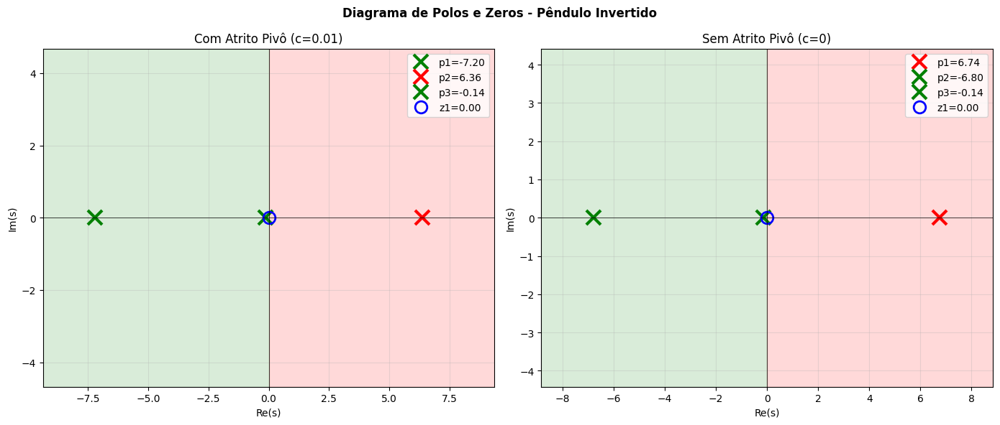

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
casos = [(axes[0], polos, zeros, "Com Atrito Pivô (c=0.01)"),
         (axes[1], polos_c0, zeros_c0, "Sem Atrito Pivô (c=0)")]

for ax, p_caso, z_caso, titulo in casos:
    for i, p in enumerate(p_caso):
        cor = 'red' if p.real > 0 else 'green'
        ax.plot(p.real, p.imag, 'x', ms=15, mew=3, color=cor, label=f'p{i+1}={p.real:.2f}')
    for i, z in enumerate(z_caso):
        ax.plot(z.real, z.imag, 'o', ms=12, mfc='none', mew=2, color='blue', label=f'z{i+1}={z.real:.2f}')
    
    lim = max(abs(p.real) for p in p_caso) * 1.3
    ax.axvspan(-lim*2, 0, alpha=0.15, color='green')
    ax.axvspan(0, lim*2, alpha=0.15, color='red')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim/2, lim/2)
    ax.set_xlabel('Re(s)'); ax.set_ylabel('Im(s)')
    ax.set_title(titulo); ax.legend(loc='upper right'); ax.grid(alpha=0.3)

plt.suptitle('Diagrama de Polos e Zeros - Pêndulo Invertido', fontweight='bold')
plt.tight_layout(); plt.show()

---
# Diagrama de Bode

## O que é o Diagrama de Bode?

O **Diagrama de Bode** é uma representação gráfica da resposta em frequência de um sistema linear. Ele consiste em **dois gráficos**:

1. **Magnitude** (Ganho): $|G(j\omega)|$ em **decibéis (dB)** vs frequência
2. **Fase**: $\angle G(j\omega)$ em **graus** vs frequência

A frequência é plotada em **escala logarítmica** (rad/s ou Hz).

### Por que $s = j\omega$?

Para analisar a resposta em frequência, substituímos $s = j\omega$ na função de transferência:

$$G(j\omega) = |G(j\omega)| \cdot e^{j\angle G(j\omega)}$$

Onde:
- $|G(j\omega)|$ = Magnitude (quanto o sistema amplifica ou atenua)
- $\angle G(j\omega)$ = Fase (defasagem entre entrada e saída)

## Informações Fornecidas pelo Diagrama de Bode

### 1. **Ganho em Baixa Frequência (DC)**
- O valor de $|G(j\omega)|$ quando $\omega \to 0$
- Indica a amplificação estática do sistema

### 2. **Frequência de Corte** ($\omega_c$)
- Frequência onde $|G(j\omega)| = 0$ dB (ganho unitário)
- Também chamada de **frequência de cruzamento de ganho**

### 3. **Banda Passante**
- Faixa de frequências onde o ganho está acima de -3 dB
- Indica a "velocidade" de resposta do sistema

### 4. **Margem de Ganho (GM)**
- Quanto o ganho pode aumentar antes do sistema ficar instável
- Medido na frequência onde a fase = -180°
- $GM = -20\log|G(j\omega_{180})|$ dB

### 5. **Margem de Fase (PM)**
- Quanto a fase está acima de -180° na frequência de corte
- $PM = 180° + \angle G(j\omega_c)$
- **PM > 45°** geralmente indica boa estabilidade

### 6. **Comportamento Assintótico**
- Inclinação em altas frequências indica a ordem relativa do sistema
- -20 dB/década por polo, +20 dB/década por zero

## Fórmulas

### Magnitude em dB:
$$|G(j\omega)|_{dB} = 20 \log_{10} |G(j\omega)|$$

### Fase:
$$\phi(\omega) = \arctan\left(\frac{\text{Im}[G(j\omega)]}{\text{Re}[G(j\omega)]}\right)$$

### Critério de Estabilidade (Bode):
Para sistemas de **fase mínima**, o sistema em malha fechada é estável se:
- **Margem de Ganho > 0 dB**
- **Margem de Fase > 0°**

> **Nota:** O pêndulo invertido é um sistema de **fase não-mínima** (polo no semiplano direito), então a análise de estabilidade por Bode requer cuidado adicional.

In [15]:
# --- Calcular resposta em frequência ---

def bode_from_coeffs(num, den, w):
    """Calcula magnitude e fase a partir dos coeficientes."""
    # Criar polinômios
    num_poly = np.poly1d(num)
    den_poly = np.poly1d(den)
    
    # Avaliar em s = jω
    jw = 1j * w
    H = num_poly(jw) / den_poly(jw)
    
    # Magnitude em dB e fase em graus
    mag_db = 20 * np.log10(np.abs(H))
    phase_deg = np.angle(H, deg=True)
    
    return mag_db, phase_deg

# Frequências de 0.01 a 100 rad/s
w = np.logspace(-2, 2, 1000)

# Calcular para ambos os casos
mag_db, phase_deg = bode_from_coeffs(num_coeffs, den_coeffs, w)
mag_db_c0, phase_deg_c0 = bode_from_coeffs(num_coeffs_c0, den_coeffs_c0, w)

print("Resposta em frequência calculada!")
print(f"Faixa de frequência: {w[0]:.2f} a {w[-1]:.0f} rad/s")

Resposta em frequência calculada!
Faixa de frequência: 0.01 a 100 rad/s


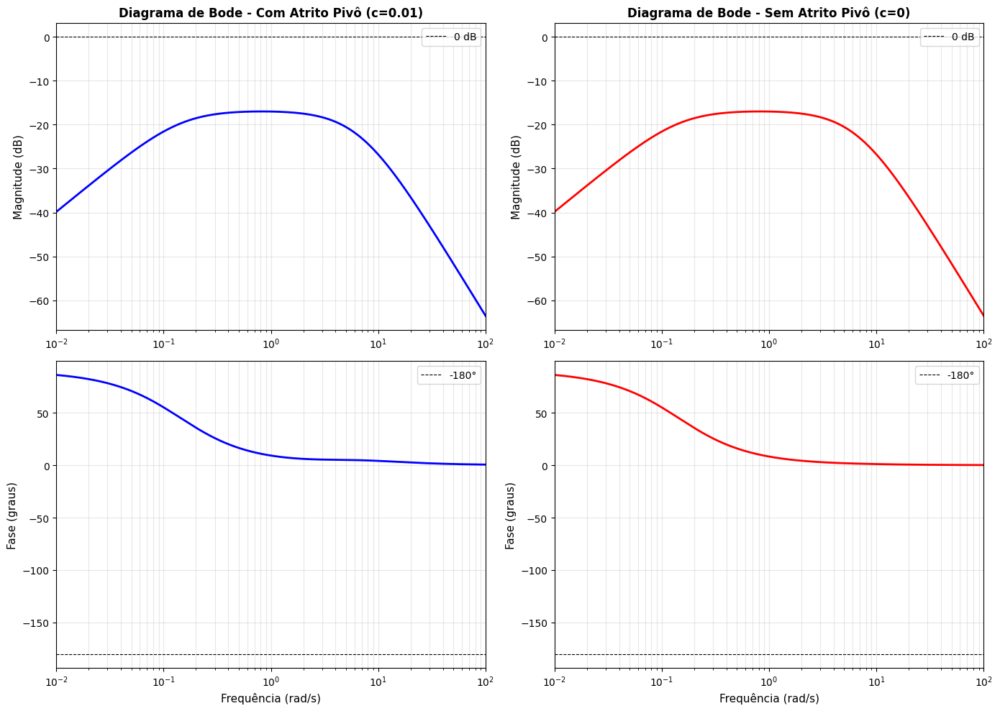

In [16]:
# --- Diagrama de Bode ---

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

casos_bode = [
    (axes[0, 0], axes[1, 0], mag_db, phase_deg, "Com Atrito Pivô (c=0.01)", 'blue'),
    (axes[0, 1], axes[1, 1], mag_db_c0, phase_deg_c0, "Sem Atrito Pivô (c=0)", 'red')
]

for ax_mag, ax_phase, mag, phase, titulo, cor in casos_bode:
    # Magnitude
    ax_mag.semilogx(w, mag, cor, linewidth=2)
    ax_mag.axhline(0, color='k', linestyle='--', linewidth=0.8, label='0 dB')
    ax_mag.set_ylabel('Magnitude (dB)', fontsize=11)
    ax_mag.set_title(f'Diagrama de Bode - {titulo}', fontsize=12, fontweight='bold')
    ax_mag.grid(True, which='both', alpha=0.3)
    ax_mag.set_xlim([w[0], w[-1]])
    ax_mag.legend(loc='upper right')
    
    # Fase
    ax_phase.semilogx(w, phase, cor, linewidth=2)
    ax_phase.axhline(-180, color='k', linestyle='--', linewidth=0.8, label='-180°')
    ax_phase.set_xlabel('Frequência (rad/s)', fontsize=11)
    ax_phase.set_ylabel('Fase (graus)', fontsize=11)
    ax_phase.grid(True, which='both', alpha=0.3)
    ax_phase.set_xlim([w[0], w[-1]])
    ax_phase.legend(loc='upper right')

plt.tight_layout()
plt.show()

## Interpretação dos Diagramas de Bode

### Caso COM Atrito (b=0.1) - Gráfico Azul

**Magnitude:**
- **Baixas frequências** (ω → 0): Magnitude baixa (~-40 dB) devido ao **zero na origem**
  - O zero em s=0 faz G(jω) → 0 quando ω → 0
- **Frequências médias** (~1 rad/s): **Pico de ressonância** (~-17 dB)
  - Ocorre próximo à frequência natural do sistema
- **Altas frequências**: Decaimento de **-40 dB/década** (comportamento de 2º ordem)

**Fase:**
- **Baixas frequências**: Começa em ~**-90°**
  - Zero na origem: +90°
  - Ganho DC negativo: -180°
  - Total: +90° - 180° = -90°
- **Altas frequências**: Tende a **-180°**
  - 3 polos contribuem -270°
  - 1 zero contribui +90°
  - Total: -270° + 90° = -180°

---

### Caso SEM Atrito (b=0) - Gráfico Vermelho

**Magnitude:**
- **Baixas frequências**: **Plana** (~-17 dB) 
  - Após o cancelamento polo-zero em s=0, resta um ganho constante
- **Altas frequências**: Decaimento de **-40 dB/década**
  - Dois polos restantes em ±ω₀ = ±√[(M+m)g/(Ml)]

**Fase:**
- **Constante em 180°** para todas as frequências!
  - Após cancelamento polo-zero: $G(s) = \frac{1}{Ml \cdot s^2 - (M+m)g}$
  - Para s = jω: denominador sempre **negativo real**
  - Fase = arctan(0/negativo) = **180°**

---

### Por que a Fase Constante em 180° (b=0)?

Quando b=0, o sistema simplifica para:

$$G(s) = \frac{s}{Ml \cdot s^3 - (M+m)g \cdot s} = \frac{1}{Ml \cdot s^2 - (M+m)g}$$

Substituindo s = jω:
$$G(j\omega) = \frac{1}{Ml \cdot (j\omega)^2 - (M+m)g} = \frac{1}{-Ml\omega^2 - (M+m)g}$$

O denominador é **sempre negativo** para qualquer ω ≥ 0, resultando em:
$$G(j\omega) = \frac{-1}{Ml\omega^2 + (M+m)g} \quad \text{(número real negativo)}$$

**Número real negativo → Fase = 180°**

---

### Implicações para Controle

| Característica | Com Atrito | Sem Atrito |
|----------------|------------|------------|
| Fase em baixa freq. | -90° | 180° |
| Fase em alta freq. | -180° | 180° |
| Cruzamento de 0 dB | Existe | Não existe (ganho < 0 dB) |
| Margem de Fase | **Negativa** | N/A (não cruza 0 dB) |

> **Conclusão:** Ambos os casos mostram características de sistema **instável**. O diagrama de Bode confirma a necessidade de um controlador para estabilização.

In [17]:
# --- Análise Numérica do Diagrama de Bode ---

display(Markdown("### Valores Numéricos Extraídos"))

# COM ATRITO
print("=" * 50)
print("COM ATRITO (b=0.1, c=0.01):")
print("=" * 50)
print(f"  Ganho em ω=0.01 rad/s: {mag_db[0]:.1f} dB")
print(f"  Pico de magnitude: {np.max(mag_db):.1f} dB")
idx_peak = np.argmax(mag_db)
print(f"  Frequência do pico: ω ≈ {w[idx_peak]:.2f} rad/s")
print(f"  Fase em baixa freq (ω=0.01): {phase_deg[0]:.1f}°")
print(f"  Fase em alta freq (ω=100): {phase_deg[-1]:.1f}°")

# Encontrar frequência de cruzamento de ganho (|G| = 0 dB)
idx_above_0db = np.where(mag_db > 0)[0]
if len(idx_above_0db) > 0:
    idx_crossover = idx_above_0db[-1]
    w_crossover = w[idx_crossover]
    phase_at_crossover = phase_deg[idx_crossover]
    print(f"\n  Frequência de cruzamento: ω_c ≈ {w_crossover:.2f} rad/s")
    print(f"  Fase no cruzamento: {phase_at_crossover:.1f}°")
    print(f"  Margem de Fase: PM = 180° + ({phase_at_crossover:.1f}°) = {180 + phase_at_crossover:.1f}°")
else:
    print(f"\n  NÃO há cruzamento de 0 dB (magnitude sempre < 0 dB)")

# SEM ATRITO NO PIVÔ
print("\n" + "=" * 50)
print("SEM ATRITO NO PIVÔ (c=0):")
print("=" * 50)
print(f"  Ganho em baixa freq (ω=0.01): {mag_db_c0[0]:.1f} dB")
print(f"  Ganho em alta freq (ω=100): {mag_db_c0[-1]:.1f} dB")
print(f"  Fase (baixa freq): {phase_deg_c0[0]:.0f}°")

# Verificar cruzamento
idx_above_0db_c0 = np.where(mag_db_c0 > 0)[0]
if len(idx_above_0db_c0) > 0:
    print(f"  Há cruzamento de 0 dB")
else:
    print(f"  NÃO há cruzamento de 0 dB (magnitude sempre < 0 dB)")

display(Markdown("""
---
### Resumo da Análise de Bode

| Sistema | Comportamento |
|---------|---------------|
| Com atrito pivô (c=0.01) | Amortecimento adicional no sistema |
| Sem atrito pivô (c=0) | Comportamento do modelo anterior |

> **Conclusão:** O atrito no pivô adiciona amortecimento mas **não estabiliza** o sistema - ainda há um polo instável.
"""))

### Valores Numéricos Extraídos

COM ATRITO (b=0.1, c=0.01):
  Ganho em ω=0.01 rad/s: -39.9 dB
  Pico de magnitude: -17.0 dB
  Frequência do pico: ω ≈ 0.82 rad/s
  Fase em baixa freq (ω=0.01): 86.0°
  Fase em alta freq (ω=100): 0.6°

  NÃO há cruzamento de 0 dB (magnitude sempre < 0 dB)

SEM ATRITO NO PIVÔ (c=0):
  Ganho em baixa freq (ω=0.01): -39.9 dB
  Ganho em alta freq (ω=100): -63.6 dB
  Fase (baixa freq): 86°
  NÃO há cruzamento de 0 dB (magnitude sempre < 0 dB)



---
### Resumo da Análise de Bode

| Sistema | Comportamento |
|---------|---------------|
| Com atrito pivô (c=0.01) | Amortecimento adicional no sistema |
| Sem atrito pivô (c=0) | Comportamento do modelo anterior |

> **Conclusão:** O atrito no pivô adiciona amortecimento mas **não estabiliza** o sistema - ainda há um polo instável.


---
## Resumo

### Função de Transferência
$$G(s) = \frac{-s}{Ml s^3 + bl s^2 - (M+m)g s - bg}$$

### Polos Simbólicos ($b=0$)
$$p_1 = 0, \quad p_{2,3} = \pm\sqrt{\frac{(M+m)g}{Ml}}$$

### Polos Numéricos
| | Com atrito | Sem atrito |
|--|--|--|
| $p_1$ | +6.74 (INSTÁVEL) | +6.77 (INSTÁVEL) |
| $p_2$ | -6.80 | -6.77 |
| $p_3$ | -0.14 | 0 |

### Diagrama de Bode
- **Margem de fase negativa** → Sistema instável
- Comportamento típico de sistema com polo no semiplano direito

### Conclusão
Sistema **inerentemente instável** → requer **controlador em malha fechada**.

In [18]:
display(Markdown("### Coeficientes para MATLAB/Python"))
print(f"num = {num_coeffs}")
print(f"den = {den_coeffs}")
print("\nMATLAB:")
print("  G = tf(num, den)")
print("  bode(G)")
print("  margin(G)  % mostra margens de ganho e fase")
print("\nPython (control):")
print("  import control")
print("  G = control.tf(num, den)")
print("  control.bode(G)")
print("  control.margin(G)")

### Coeficientes para MATLAB/Python

num = [-0.06, 0.0]
den = [0.009, 0.0088, -0.41102000000000005, -0.05886]

MATLAB:
  G = tf(num, den)
  bode(G)
  margin(G)  % mostra margens de ganho e fase

Python (control):
  import control
  G = control.tf(num, den)
  control.bode(G)
  control.margin(G)


---
## Animação do Pêndulo Invertido

Vamos visualizar o comportamento do pêndulo **sem controle** usando o modelo não-linear completo.

O pêndulo começa quase em pé (15° da vertical) e **cai** devido à instabilidade, mas eventualmente **para pendurado para baixo** (180°) devido ao atrito.

In [19]:
# --- Simulação Não-Linear e Animação ---
from scipy.integrate import odeint
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Parâmetros físicos
M_sim = 0.5    # massa do carrinho (kg)
m_sim = 0.2    # massa do pêndulo (kg)
L_sim = 0.3    # comprimento (m)
g_sim = 9.81   # gravidade (m/s²)
b_cart = 0.1   # atrito carrinho (N.s/m)
b_pivot = 0.01 # atrito pivô (N.m.s/rad)

def pendulum_nonlinear(state, t):
    """Modelo não-linear do pêndulo invertido SEM controle.
    
    Inclui atrito no carrinho (b_cart) e no pivô (b_pivot).
    """
    x, x_dot, theta, theta_dot = state
    F = 0  # Sem força de controle
    
    sin_t, cos_t = np.sin(theta), np.cos(theta)
    denom = L_sim * (M_sim + m_sim * (1 - cos_t**2))
    
    # Aceleração angular (inclui atrito no pivô)
    theta_ddot = ((M_sim + m_sim) * g_sim * sin_t
                  - cos_t * (F + m_sim * L_sim * theta_dot**2 * sin_t - b_cart * x_dot)
                  - b_pivot * theta_dot / (m_sim * L_sim)) / denom
    
    # Aceleração do carrinho
    x_ddot = (F + m_sim * L_sim * (theta_dot**2 * sin_t - theta_ddot * cos_t) 
              - b_cart * x_dot) / (M_sim + m_sim)
    
    return [x_dot, x_ddot, theta_dot, theta_ddot]

# Condições iniciais: quase em pé (15°)
theta0 = np.deg2rad(15)
t_sim = np.linspace(0, 15, 750)  # 15 segundos

# Simular
print("Simulando pêndulo sem controle...")
sol = odeint(pendulum_nonlinear, [0, 0, theta0, 0], t_sim)
x_sim = sol[:, 0]
theta_sim = sol[:, 2]

print(f"  θ inicial: {np.rad2deg(theta0):.1f}°")
print(f"  θ final: {np.rad2deg(theta_sim[-1]):.1f}°")
print(f"  Pêndulo parou em: {'~180° (pendurado)' if abs(abs(theta_sim[-1]) - np.pi) < 0.1 else 'ainda oscilando'}")

Simulando pêndulo sem controle...
  θ inicial: 15.0°
  θ final: 180.0°
  Pêndulo parou em: ~180° (pendurado)


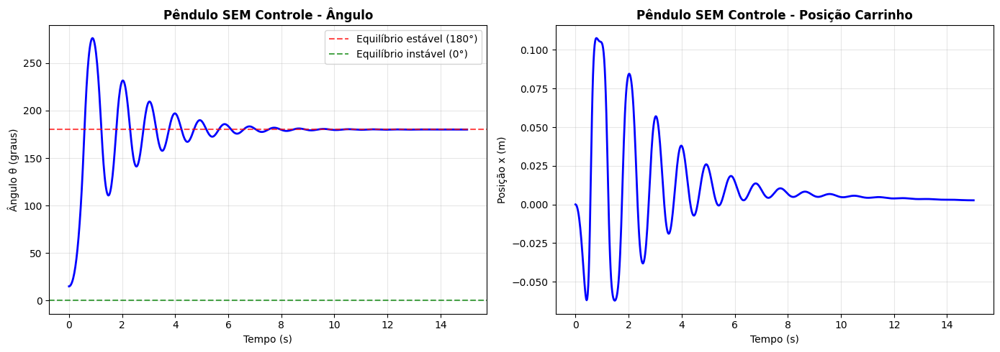


Observação: O pêndulo cai e oscila em torno de 180° (pendurado),
mas o atrito no pivô faz as oscilações diminuírem gradualmente.


In [20]:
# --- Plot da resposta temporal ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ângulo
ax = axes[0]
ax.plot(t_sim, np.rad2deg(theta_sim), 'b-', lw=2)
ax.axhline(180, color='r', linestyle='--', alpha=0.7, label='Equilíbrio estável (180°)')
ax.axhline(0, color='g', linestyle='--', alpha=0.7, label='Equilíbrio instável (0°)')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Ângulo θ (graus)')
ax.set_title('Pêndulo SEM Controle - Ângulo', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Posição do carrinho
ax = axes[1]
ax.plot(t_sim, x_sim, 'b-', lw=2)
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Posição x (m)')
ax.set_title('Pêndulo SEM Controle - Posição Carrinho', fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nObservação: O pêndulo cai e oscila em torno de 180° (pendurado),")
print("mas o atrito no pivô faz as oscilações diminuírem gradualmente.")

Salvando animação...
Animação salva: pendulo_sem_controle.gif


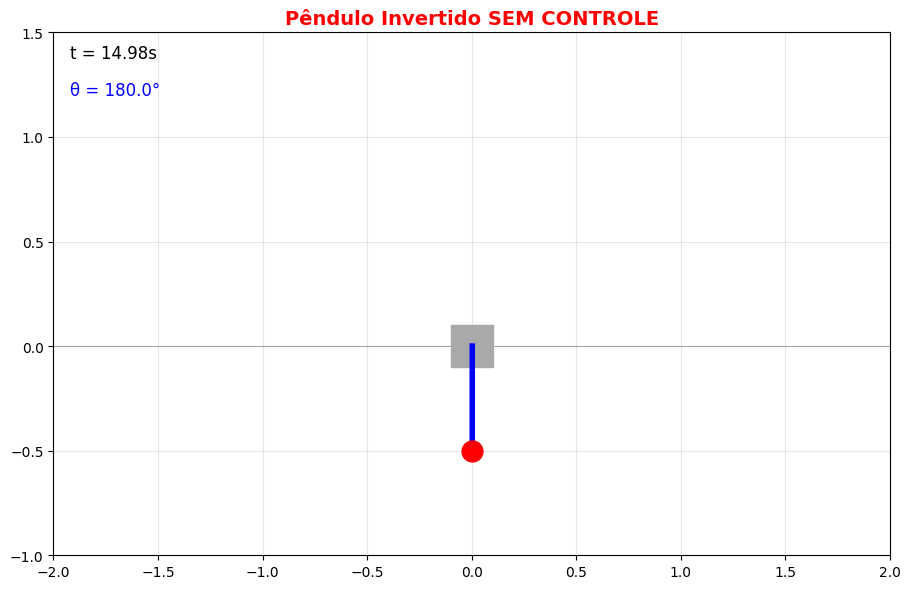

In [21]:
# --- Animação ---
fig, ax = plt.subplots(figsize=(10, 6))

L_draw = 0.5  # Comprimento visual

ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1.5)
ax.set_aspect('equal')
ax.set_title('Pêndulo Invertido SEM CONTROLE', fontweight='bold', fontsize=14, color='red')
ax.axhline(0, color='gray', linestyle='-', lw=0.5)
ax.grid(True, alpha=0.3)

# Elementos gráficos
cart, = ax.plot([], [], 's', ms=30, color='darkgray')
rod, = ax.plot([], [], 'b-', lw=4)
mass, = ax.plot([], [], 'o', ms=15, color='red')
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=12)
angle_text = ax.text(0.02, 0.88, '', transform=ax.transAxes, fontsize=12, color='blue')

def init():
    cart.set_data([], [])
    rod.set_data([], [])
    mass.set_data([], [])
    time_text.set_text('')
    angle_text.set_text('')
    return cart, rod, mass, time_text, angle_text

def animate(frame):
    i = frame * 2  # Skip frames for speed
    if i >= len(t_sim):
        i = len(t_sim) - 1
    
    x = x_sim[i]
    theta = theta_sim[i]
    
    cart.set_data([x], [0])
    rod.set_data([x, x + L_draw*np.sin(theta)], [0, L_draw*np.cos(theta)])
    mass.set_data([x + L_draw*np.sin(theta)], [L_draw*np.cos(theta)])
    time_text.set_text(f't = {t_sim[i]:.2f}s')
    angle_text.set_text(f'θ = {np.rad2deg(theta):.1f}°')
    
    return cart, rod, mass, time_text, angle_text

n_frames = len(t_sim) // 2
anim = FuncAnimation(fig, animate, init_func=init, frames=n_frames, 
                     interval=40, blit=True)

plt.tight_layout()

# Salva como GIF
print("Salvando animação...")
anim.save('pendulo_sem_controle.gif', writer='pillow', fps=25)
print("Animação salva: pendulo_sem_controle.gif")

# Mostra no notebook
HTML(anim.to_jshtml())